# NarrativeCast — ND3.4a · v5 Quality Audit for Full POST Discovery

**Kế thừa trực tiếp v4** (`full_post_v4`, `run_hash=e7480e1fd1620bc2`): 751.607 POST, `all-MiniLM-L6-v2`, 384D, 94 embedding shards, 120 cụm MiniBatchKMeans *exploratory*. **Không mã hóa embedding lại, không fit lại KMeans, không sửa nguồn v4.**

**Vì sao v5 cần thiết?** Review v4 chỉ có 12 câu *gần tâm* mỗi cụm nên không đo được độ thuần của toàn cụm. v5 xuất **mẫu ngẫu nhiên có xác suất**, **mẫu trung tâm/rìa có chủ đích**, **mẫu theo năm**, **mẫu ngẫu nhiên toàn corpus** và phiếu chấm độc lập. Chỉ nhãn người duyệt mới được dùng để tính precision/contamination. Cluster của KMeans **không đồng nghĩa với narrative/framing**.

**Sản phẩm** trong `data/interim/task4/full_post_v4/quality_audit_v5/<audit_id>/`: sampling manifest, review_queue_source.csv, review_queue_A.csv, review_queue_B_overlap.csv, cluster profiles, quality_report (chỉ khi có nhãn), QA manifest.

> **Quy tắc:** Không thay `is_usable_text`, không xóa spam khỏi Parquet gốc, không tự chọn chủ đề. Không lấy số bản ghi được gán cụm làm số bài đúng chủ đề. Hoàn thành v5 cần **duyệt nhãn thật** trước khi lựa chọn ngách.

## 1 — Thiết lập trên Google Colab
Chạy sau khi v4 đạt `PASS`; chỉ cần CPU và Drive. Không cần cài `sentence-transformers` hay GPU để lấy mẫu/review.

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)
from pathlib import Path
import json, hashlib, os, gc, math, warnings
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path('/content/drive/MyDrive/NarrativeCast')
V4 = ROOT / 'data/interim/task4/full_post_v4'
ACCEPT_FILE = V4 / 'full_post_acceptance.json'
ASSIGN_FILE = V4 / 'exploratory_post_assignments.csv'
REGISTRY_FILE = V4 / 'post_registry.csv'
SIZE_FILE = V4 / 'exploratory_cluster_sizes.csv'
MONTH_FILE = V4 / 'post_monthly.csv'

# Không đổi lựa chọn chủ đề dựa vào clustering ở notebook này.
CANDIDATES = {
    44: 'Net neutrality / FCC',
    50: 'Apple-FBI / iPhone encryption',
    114: 'Encryption, surveillance and law enforcement',
    73: 'Facebook / misinformation / platform responsibility',
    85: 'Data protection law',
    71: 'Bitcoin / cryptocurrency',
    5: 'AI / automation future',
    75: 'Self-driving vehicles',
    72: 'Solar energy cost and deployment',
    89: 'Amazon and market power',
}
SPAM_REVIEW_CLUSTERS = {9,12,13,14,25,32,42,54,59,74,76,77,82,86,93,119}
LANG_REVIEW_CLUSTERS = {16,43,57,58,108,112,116}
DIAGNOSTIC_CLUSTERS = {20} # Trường hợp COVID: gán 2014-2019 vẫn phải đánh giá.

CFG = {
    'seed': 20261107,
    'global_srs': 350,
    'candidate_random': 80,
    'candidate_near': 6,
    'candidate_far': 6,
    'candidate_per_year': 2,
    'risk_random': 18,
    'risk_near': 3,
    'risk_far': 3,
    'other_random': 4,
    'other_near': 2,
    'other_far': 2,
    'double_review_fraction': 0.30,
    'min_candidate_random_labels': 60,
}

for p in [ACCEPT_FILE, ASSIGN_FILE, REGISTRY_FILE, SIZE_FILE, MONTH_FILE]:
    assert p.is_file(), f'MISSING v4 file: {p}'
accept = json.loads(ACCEPT_FILE.read_text())
assert accept['status'] == 'PASS', 'v4 chưa PASS'
assert accept['model'] == 'sentence-transformers/all-MiniLM-L6-v2'
assert int(accept['embedding_dim']) == 384
assert int(accept['months']) == 84
assert not accept.get('scope_selected', False), 'v4 trước đó đã chốt scope: kiểm lại trạng thái'
RUN_HASH = accept['run_hash']
AUDIT_ID = hashlib.sha256(json.dumps({'run_hash': RUN_HASH, 'cfg': CFG, 'candidate_ids': sorted(CANDIDATES)}, sort_keys=True).encode()).hexdigest()[:12]
OUT = V4 / 'quality_audit_v5' / AUDIT_ID
OUT.mkdir(parents=True, exist_ok=True)
print('V4:', V4, '\nAUDIT_ID:', AUDIT_ID, '\nOUTPUT:', OUT)
print('NO RE-EMBEDDING; NO KMEANS REFIT')

Mounted at /content/drive
V4: /content/drive/MyDrive/NarrativeCast/data/interim/task4/full_post_v4 
AUDIT_ID: b33a176368c2 
OUTPUT: /content/drive/MyDrive/NarrativeCast/data/interim/task4/full_post_v4/quality_audit_v5/b33a176368c2
NO RE-EMBEDDING; NO KMEANS REFIT


## 2 — Kiểm tra toàn bộ bảng gán cụm và lịch tháng
Đọc tất cả 751.607 assignments bằng CPU; đối chiếu 120 cụm và 84 tháng. Nếu không khớp sẽ **dừng**.

In [2]:
a = pd.read_csv(ASSIGN_FILE, dtype={'post_id':'string'})
assert set(['post_id','publish_datetime_utc','exploratory_cluster_id','centroid_distance']).issubset(a.columns)
a['post_id'] = a['post_id'].astype(str)
a['publish_datetime_utc'] = pd.to_datetime(a['publish_datetime_utc'], utc=True, errors='raise')
a['exploratory_cluster_id'] = pd.to_numeric(a['exploratory_cluster_id'], errors='raise').astype(int)
a['centroid_distance'] = pd.to_numeric(a['centroid_distance'], errors='raise').astype(float)
a['year'] = a['publish_datetime_utc'].dt.year
a_invalid = (~np.isfinite(a['centroid_distance'])).sum()
assert a_invalid == 0
assert a['post_id'].notna().all() and a['post_id'].is_unique
assert len(a) == int(accept['full_post_rows']) == 751607
assert a['exploratory_cluster_id'].nunique() == 120
assert a['year'].between(2014, 2020).all()
assert a['publish_datetime_utc'].dt.strftime('%Y-%m').nunique() == 84
sizes = pd.read_csv(SIZE_FILE)
expected_sizes = sizes.set_index('cluster_id')['post_count'].astype(int).sort_index()
observed_sizes = a.groupby('exploratory_cluster_id').size().sort_index()
assert expected_sizes.equals(observed_sizes), 'cluster_size totals differ'
months = pd.read_csv(MONTH_FILE).set_index('month')['post_count'].astype(int).sort_index()
observed_months = a['publish_datetime_utc'].dt.strftime('%Y-%m').value_counts().sort_index()
assert months.equals(observed_months), 'monthly totals differ'
assert set(CANDIDATES).issubset(set(expected_sizes.index))
print('INPUT PASS | rows:',len(a),'unique IDs:',a.post_id.nunique(), 'clusters:',len(expected_sizes),'months:',len(months))

INPUT PASS | rows: 751607 unique IDs: 751607 clusters: 120 months: 84


## 3 — Thống kê toàn dữ liệu (không dùng mẫu để suy ra prevalence)
`cluster_annual_profile.csv` và `cluster_monthly_profile.csv` là số lượng **được KMeans gán**, không phải số đúng chủ đề. `median_distance` và `p90` chỉ là độ gần tâm tương đối.

In [3]:
a['month'] = a['publish_datetime_utc'].dt.strftime('%Y-%m')
summary = (a.groupby('exploratory_cluster_id')
           .agg(assigned_post_count=('post_id','size'),
                median_distance=('centroid_distance','median'),
                p90_distance=('centroid_distance',lambda x:x.quantile(0.9)),
                p95_distance=('centroid_distance',lambda x:x.quantile(0.95)),
                first_utc=('publish_datetime_utc','min'),
                last_utc=('publish_datetime_utc','max')).reset_index())
summary['assigned_share_pct'] = 100*summary.assigned_post_count/len(a)
summary['candidate_hint'] = summary.exploratory_cluster_id.map(CANDIDATES).fillna('')
summary['risk_flag'] = summary.exploratory_cluster_id.map(
    lambda k: 'POSSIBLE_SPAM' if k in SPAM_REVIEW_CLUSTERS else
              'POSSIBLE_NON_ENGLISH' if k in LANG_REVIEW_CLUSTERS else
              'TEMPORAL_CONTRADICTION_CHECK' if k in DIAGNOSTIC_CLUSTERS else '')
monthly=(a.groupby(['exploratory_cluster_id','month']).size().rename('assigned_post_count').reset_index())
monthly['all_post_count_month']=monthly['month'].map(months).astype(int)
monthly['assigned_share_pct_month']=100*monthly.assigned_post_count/monthly.all_post_count_month
annual=(a.groupby(['exploratory_cluster_id','year']).size().rename('assigned_post_count').reset_index())
year_total=a.groupby('year').size()
annual['all_post_count_year']=annual['year'].map(year_total)
annual['assigned_share_pct_year']=100*annual.assigned_post_count/annual.all_post_count_year
for name,d in [('cluster_summary_v5.csv',summary),('cluster_monthly_profile.csv',monthly),('cluster_annual_profile.csv',annual)]:
    d.to_csv(OUT/name,index=False)
print('Saved cluster profiles (assigned counts, NOT gold topic prevalence)')
display(summary.loc[summary.exploratory_cluster_id.isin(CANDIDATES)].sort_values('assigned_post_count',ascending=False))

Saved cluster profiles (assigned counts, NOT gold topic prevalence)


,exploratory_cluster_id,assigned_post_count,median_distance,p90_distance,p95_distance,first_utc,last_utc,assigned_share_pct,candidate_hint,risk_flag
44,44,8565,0.726301,0.826793,0.858940,2014-01-06 21:40:29+00:00,2020-12-29 00:47:37+00:00,1.139558,Net neutrality / FCC,
85,85,8036,0.857805,0.931426,0.948625,2014-01-01 04:08:27+00:00,2020-12-31 15:34:15+00:00,1.069176,Data protection law,
5,5,7913,0.817581,0.907448,0.929171,2014-01-01 16:47:36+00:00,2020-12-30 17:38:12+00:00,1.052811,AI / automation future,
75,75,7813,0.847960,0.927575,0.947450,2014-01-01 00:38:26+00:00,2020-12-30 06:11:19+00:00,1.039506,Self-driving vehicles,
72,72,7457,0.854483,0.934168,0.952220,2014-01-01 08:27:01+00:00,2020-12-30 18:53:46+00:00,0.992141,Solar energy cost and deployment,
114,114,7420,0.828558,0.908898,0.928238,2014-01-01 16:51:37+00:00,2020-12-31 01:07:38+00:00,0.987218,"Encryption, surveillance and law enforcement",
73,73,7386,0.823065,0.904737,0.920211,2014-01-02 01:54:06+00:00,2020-12-31 21:26:23+00:00,0.982694,Facebook / misinformation / platform responsib...,
71,71,6447,0.838082,0.912438,0.934142,2014-01-01 19:20:35+00:00,2020-12-31 17:37:54+00:00,0.857762,Bitcoin / cryptocurrency,
89,89,5792,0.824573,0.894974,0.915160,2014-01-01 15:55:21+00:00,2020-12-31 18:21:46+00:00,0.770615,Amazon and market power,
50,50,4112,0.820047,0.917239,0.939536,2014-01-01 01:14:15+00:00,2020-12-31 23:02:07+00:00,0.547094,Apple-FBI / iPhone encryption,


## 4 — Thiết kế mẫu *không thiên vị trung tâm*
**Vai trò mẫu:**
- `global_random`: 350 POST lấy ngẫu nhiên trên **toàn bộ** 751.607 để tìm chủ đề bị bỏ sót và nghi ngờ spam; không dùng làm mô tả topic precision của cụm riêng lẻ.
- `cluster_random`: mẫu ngẫu nhiên có xác suất trong từng cụm, **chỉ nhóm này dùng để ước lượng** topic fit / contamination cụm.
- `near_centroid` và `far_centroid`: trường hợp điển hình và gần biên / ngoài tâm, dùng *diagnostics*, **không cộng vào mẫu ngẫu nhiên**.
- `temporal_year`: chọn vài bài mỗi năm trong 10 cụm ứng viên để phát hiện chủ đề bị trộn theo thời gian. Không dùng đo precision toàn cụm.
- `temporal_control`: kiểm tra riêng cụm 20 (COVID: trước 2020 vs năm 2020).

Chọn mẫu cố định bằng hash ID + seed; một bài chỉ có **một** hàng review. Chúng ta không gọi các cụm là narrative, và không tự điền nhãn người đọc.

In [4]:
# Mã thực thi thuần Python, có thể test bằng data synthetic ở cell kế tiếp.
def choose_indices(remaining, n, sort_by):
    if n <= 0 or remaining.empty:
        return []
    cols = {'random':['random_key','post_id'],
            'near':['centroid_distance','post_id'],
            'far':['centroid_distance','post_id']}[sort_by]
    asc = [False, True] if sort_by=='far' else [True, True]
    return remaining.sort_values(cols, ascending=asc, kind='mergesort').index[:n].tolist()

def generate_sampling_table(frame, cfg, candidate_map, spam_ids, lang_ids, diagnostic_ids):
    required = {'post_id','publish_datetime_utc','exploratory_cluster_id','centroid_distance','year'}
    assert required.issubset(frame.columns)
    assert frame.post_id.is_unique
    x=frame.copy()
    seed=str(cfg['seed'])
    x['random_key'] = pd.util.hash_pandas_object(x['post_id'].astype(str) + '|' + seed, index=False).astype('uint64')
    used=set(); selections=[]
    def put(indices, role, inclusion_probability=np.nan):
        for idx in indices:
            if idx in used: raise AssertionError('double sampled row')
            used.add(idx)
            selections.append((idx,role,float(inclusion_probability) if not pd.isna(inclusion_probability) else np.nan))
    idx=choose_indices(x,cfg['global_srs'],'random')
    put(idx,'global_random',len(idx)/len(x))
    for k, group in x.groupby('exploratory_cluster_id', sort=True):
        k=int(k)
        if k in candidate_map:
            nr,nn,nf=cfg['candidate_random'],cfg['candidate_near'],cfg['candidate_far']
        elif k in spam_ids or k in lang_ids or k in diagnostic_ids:
            nr,nn,nf=cfg['risk_random'],cfg['risk_near'],cfg['risk_far']
        else:
            nr,nn,nf=cfg['other_random'],cfg['other_near'],cfg['other_far']
        remaining=group.loc[~group.index.isin(used)]
        idx=choose_indices(remaining,nr,'random')
        # Simple random sample from group AFTER independent corpus-global sample.
        put(idx,'cluster_random',len(idx)/len(remaining))
        remaining=group.loc[~group.index.isin(used)]
        put(choose_indices(remaining,nn,'near'),'near_centroid')
        remaining=group.loc[~group.index.isin(used)]
        put(choose_indices(remaining,nf,'far'),'far_centroid')
        if k in candidate_map:
            for year, ygroup in group.groupby('year',sort=True):
                remaining=ygroup.loc[~ygroup.index.isin(used)]
                put(choose_indices(remaining,cfg['candidate_per_year'],'random'),'temporal_year')
        if k in diagnostic_ids:
            # Purposeful contrast: cluster #20 before vs during 2020.
            for mask in [group['year'] < 2020, group['year'] == 2020]:
                remaining=group.loc[mask & ~group.index.isin(used)]
                put(choose_indices(remaining,8,'random'),'temporal_control')
    take=pd.DataFrame(selections,columns=['row_index','sampling_role','sampling_probability'])
    out=x.loc[take.row_index].copy().reset_index(drop=True)
    out['sampling_role']=take.sampling_role.to_numpy()
    out['sampling_probability']=take.sampling_probability.to_numpy()
    out['review_id']=['R'+hashlib.sha256((seed+'|'+pid).encode()).hexdigest()[:16] for pid in out.post_id]
    out['candidate_topic_hint']=out['exploratory_cluster_id'].map(candidate_map).fillna('OTHER_OR_UNSCOPED')
    out['priority_tier']=out.exploratory_cluster_id.map(
        lambda k:'1_CANDIDATE' if k in candidate_map else
        '2_RISK' if k in spam_ids or k in lang_ids or k in diagnostic_ids else '3_OTHER')
    out['month']=out['publish_datetime_utc'].dt.strftime('%Y-%m')
    out=out.drop(columns=['random_key'])
    return out.sort_values(['priority_tier','exploratory_cluster_id','sampling_role','year','review_id']).reset_index(drop=True)

### 4.1 — Tự kiểm tra sampler trên dữ liệu giả
Chạy test này để phát hiện lấy trùng một ID, tính ngẫu nhiên không ổn định hoặc thiếu strata. **Không dùng dữ liệu giả để đánh giá đề tài**.

In [5]:
fixture=pd.DataFrame({
 'post_id':[f'fake{i:04d}' for i in range(240)],
 'publish_datetime_utc':pd.date_range('2014-01-01',periods=240,freq='D',tz='UTC'),
 'exploratory_cluster_id':np.repeat(np.arange(4),60),
 'centroid_distance':np.linspace(0.1,1.4,240),
})
fixture['year']=fixture.publish_datetime_utc.dt.year
fc={**CFG,'global_srs':15,'candidate_random':10,'candidate_near':3,'candidate_far':3,
    'risk_random':6,'risk_near':2,'risk_far':2,'other_random':5,'other_near':2,'other_far':2,'candidate_per_year':1}
fx1=generate_sampling_table(fixture,fc,{0:'TEST_TOPIC'},{1},{2},{3})
fx2=generate_sampling_table(fixture,fc,{0:'TEST_TOPIC'},{1},{2},{3})
assert fx1.review_id.is_unique and fx1.post_id.is_unique
assert fx1[['post_id','sampling_role']].equals(fx2[['post_id','sampling_role']])
assert set(fx1.sampling_role).issuperset({'global_random','cluster_random','near_centroid','far_centroid','temporal_year','temporal_control'})
print('SAMPLER SELF-TEST PASS:',len(fx1),'unique sampled IDs; reproducible')
del fixture,fx1,fx2;gc.collect()

SAMPLER SELF-TEST PASS: 70 unique sampled IDs; reproducible


70

### 4.2 — Chọn mẫu từ **toàn bộ** 751.607 assignments
Vì cấu hình dùng `AUDIT_ID`, chạy lại sẽ dùng lại manifest; không ghi đè phiếu review đã chấm.

In [6]:
SAMPLE_FILE=OUT/'sample_manifest.csv'
if SAMPLE_FILE.exists():
    sample=pd.read_csv(SAMPLE_FILE, dtype={'post_id':'string','review_id':'string'})
    sample['publish_datetime_utc']=pd.to_datetime(sample['publish_datetime_utc'],utc=True)
    print('REUSE saved sample manifest:',len(sample))
else:
    sample=generate_sampling_table(a,CFG,CANDIDATES,SPAM_REVIEW_CLUSTERS,LANG_REVIEW_CLUSTERS,DIAGNOSTIC_CLUSTERS)
    sample.to_csv(SAMPLE_FILE,index=False)
    print('SAVE NEW sample manifest:',len(sample))
assert sample.post_id.is_unique and sample.review_id.is_unique
assert set(sample.post_id).issubset(set(a.post_id))
print('Sampling role counts:')
print(sample.sampling_role.value_counts().to_string())
print('Priority tiers:')
print(sample.priority_tier.value_counts().to_string())
print('Candidate YEAR coverage:')
display(sample[(sample.priority_tier=='1_CANDIDATE') & sample.sampling_role.eq('temporal_year')]
       .groupby(['exploratory_cluster_id','year']).size().unstack(fill_value=0))

SAVE NEW sample manifest: 2690
Sampling role counts:
sampling_role
cluster_random      1576
global_random        350
far_centroid         304
near_centroid        304
temporal_year        140
temporal_control      16
Priority tiers:
priority_tier
1_CANDIDATE    1091
3_OTHER         960
2_RISK          639
Candidate YEAR coverage:


year,2014,2015,2016,2017,2018,2019,2020
exploratory_cluster_id,,,,,,,
5,2,2,2,2,2,2,2
44,2,2,2,2,2,2,2
50,2,2,2,2,2,2,2
71,2,2,2,2,2,2,2
72,2,2,2,2,2,2,2
73,2,2,2,2,2,2,2
75,2,2,2,2,2,2,2
85,2,2,2,2,2,2,2
89,2,2,2,2,2,2,2


## 5 — Ghép nội dung POST thật từ registry v4 theo `post_id`
Đọc `post_registry.csv` theo chunk, chỉ giữ những ID đã chọn; **không** đọc 94 NPZ. Check ID đầy đủ và timestamp tương ứng. Phiếu review sẽ chứa nguyên văn `content`, không rút gọn và không thay bằng văn bản giả.

In [7]:
SOURCE_REVIEW=OUT/'review_queue_source.csv'
if SOURCE_REVIEW.exists():
    review=pd.read_csv(SOURCE_REVIEW,dtype={'post_id':'string','review_id':'string'},keep_default_na=False)
    assert len(review)==len(sample) and set(review.post_id)==set(sample.post_id)
    assert review['content'].astype(str).str.strip().ne('').all()
    print('REUSE existing review source (never overwrite annotations):',len(review))
else:
    targets=set(sample.post_id.astype(str))
    found=[];seen=set();scanned=0
    for chunk in pd.read_csv(REGISTRY_FILE,chunksize=50000, dtype={'post_id':'string'},keep_default_na=False,
                             usecols=['post_id','content','publish_datetime_utc']):
        scanned+=len(chunk)
        sub=chunk[chunk.post_id.astype(str).isin(targets)]
        if len(sub):
            ids=set(sub.post_id.astype(str))
            assert len(ids)==len(sub) and not (seen & ids), 'Duplicated selected post_id in registry'
            seen.update(ids)
            found.append(sub)
    assert scanned==int(accept['full_post_rows']), f'registry rows {scanned} != {accept["full_post_rows"]}'
    reg_selected=pd.concat(found,ignore_index=True)
    assert set(reg_selected.post_id.astype(str))==targets, 'Missing selected content in v4 registry'
    reg_selected['post_id']=reg_selected['post_id'].astype(str)
    reg_selected['publish_datetime_utc']=pd.to_datetime(reg_selected['publish_datetime_utc'],utc=True,errors='raise')
    review=sample.merge(reg_selected,on='post_id',how='left',validate='one_to_one',suffixes=('_assign','_registry'))
    assert (review.publish_datetime_utc_assign==review.publish_datetime_utc_registry).all(), 'Timestamp mismatch'
    review=review.drop(columns=['publish_datetime_utc_registry']).rename(columns={'publish_datetime_utc_assign':'publish_datetime_utc'})
    assert review.content.notna().all() and review.content.astype(str).str.strip().ne('').all()
    review.to_csv(SOURCE_REVIEW,index=False)
    print('REGISTRY JOIN PASS | scanned',scanned,'| sampled',len(review),'| content complete')
    del reg_selected,found,seen
print('Sample content preview:')
display(review[['review_id','sampling_role','candidate_topic_hint','year','content']].head(8))

REGISTRY JOIN PASS | scanned 751607 | sampled 2690 | content complete
Sample content preview:


,review_id,sampling_role,candidate_topic_hint,year,content
0,R176a68b5e0937f03,cluster_random,AI / automation future,2014,Earlier on reddit I saw a post about Bill Gate...
1,R22dac09c72293006,cluster_random,AI / automation future,2014,"""We've lost the sense of what's actually happe..."
2,R0e42ab38ccd49f82,cluster_random,AI / automation future,2015,Reddit extract cognitive work from comments to...
3,R3a02818b0306d1ef,cluster_random,AI / automation future,2015,Video Shows Google’s DeepMind AI Computer Comp...
4,R6395e4ef2d2d77cf,cluster_random,AI / automation future,2015,"Paired With AI and VR, Google Earth Will Chang..."
5,Rc6101aa50b1174bc,cluster_random,AI / automation future,2015,"Would Artificial Intelligence (AI) develop ""me..."
6,Rcaf88dfcdb9aaf71,cluster_random,AI / automation future,2015,io9: Leading Experts Sign an Open Letter Calli...
7,R41a2135115c32bce,cluster_random,AI / automation future,2016,Google: Scary-smart AI still 'decades and deca...


## 6 — Xuất phiếu review người thật (A và B)
**Hướng dẫn cho người chấm:**

1. `topic_fit`: `YES`, `NO`, `UNCERTAIN` — bài có thật sự thuộc chủ đề gợi ý của cụm không? Với `OTHER_OR_UNSCOPED`, dùng `primary_topic` để ghi đề tài thật, để phát hiện chủ đề mới. Với `global_random`, xem kỹ `primary_topic` và đừng áp tiêu chí của một cụm bất kỳ.
2. `quality_flag`: `CLEAN`, `SPAM_PROMO`, `NON_ENGLISH`, `OTHER_LOW_QUALITY`, `UNCERTAIN`. Nếu một bài có nhiều lỗi, ghi thêm `review_notes`.
3. `stance_or_framing`: tóm tắt quan điểm (ủng hộ, phản đối, hoài nghi, điều kiện...); không đồng nhất sentiment với stance.
4. `claim_summary`: một câu nêu **luận điểm** nếu có; bài chỉ nêu tên sản phẩm/chủ đề mà không có claim thì ghi `NO_CLAIM`.
5. Chỉ sử dụng bài viết thật trong `content`. Không dựa vào `cluster_id` để tự động cho `YES`.

**B chấm độc lập** một phần giao thoa cố định khoảng 30%, không được xem nhãn A trước khi khóa kết quả. Nếu chưa chấm thì không tạo precision/κ giả. Hai phiếu có cùng `review_id` cho các câu giao thoa.

In [8]:
ANNOTATION_COLS=['topic_fit','quality_flag','primary_topic','stance_or_framing','claim_summary','review_notes']
fixed_cols=['review_id','post_id','exploratory_cluster_id','sampling_role','sampling_probability',
            'candidate_topic_hint','priority_tier','centroid_distance','year','month','publish_datetime_utc','content']
queue=review[fixed_cols].copy()
for col in ANNOTATION_COLS:queue[col]=''
A_FILE=OUT/'review_queue_A.csv'
if A_FILE.exists():
    old=pd.read_csv(A_FILE,dtype={'review_id':'string'})
    assert set(old.review_id)==set(queue.review_id),'A file does not match current deterministic sample'
    print('PRESERVE EXISTING REVIEWER A:',len(old))
else:
    queue.to_csv(A_FILE,index=False)
    print('CREATED reviewer A:',len(queue))

# B: choose deterministic, independent fixed overlap within each role × candidate/risk class.
mask=(pd.util.hash_pandas_object(queue.review_id+'|reviewer_B|'+str(CFG['seed']),index=False)
      .astype('uint64') / float(2**64) < CFG['double_review_fraction'])
qB=queue.loc[mask].copy()
B_FILE=OUT/'review_queue_B_overlap.csv'
if B_FILE.exists():
    old=pd.read_csv(B_FILE,dtype={'review_id':'string'})
    assert set(old.review_id)==set(qB.review_id),'B file does not match overlap'
    print('PRESERVE EXISTING REVIEWER B:',len(old))
else:
    qB.to_csv(B_FILE,index=False)
    print('CREATED reviewer B overlap:',len(qB),'fraction',round(len(qB)/len(queue),3))

rubric={
 'topic_fit':['YES','NO','UNCERTAIN'],
 'quality_flag':['CLEAN','SPAM_PROMO','NON_ENGLISH','OTHER_LOW_QUALITY','UNCERTAIN'],
 'primary_topic':'short descriptive free text; for GLOBAL random this screens missed topics',
 'stance_or_framing':'short free text; no automatic narrative label',
 'claim_summary':'one-sentence claim, or NO_CLAIM',
 'review_notes':'free text with doubt, misleading fit, reason for exclusion',
 'measurement_rule':'topic precision and contamination only from cluster_random labels; do not pool purposive near/far/temporal',
 'design':'global_random is independent, probability sample; core/edge and year cases are diagnostics',
}
(OUT/'review_rubric.json').write_text(json.dumps(rubric,indent=2,ensure_ascii=False),encoding='utf-8')
print('Review files:',A_FILE,B_FILE)

CREATED reviewer A: 2690
CREATED reviewer B overlap: 823 fraction 0.306
Review files: /content/drive/MyDrive/NarrativeCast/data/interim/task4/full_post_v4/quality_audit_v5/b33a176368c2/review_queue_A.csv /content/drive/MyDrive/NarrativeCast/data/interim/task4/full_post_v4/quality_audit_v5/b33a176368c2/review_queue_B_overlap.csv


## 7 — Kiểm định biểu đồ thời gian (chỉ dựa assignments)
Tạo biểu đồ 10 cụm ứng viên. **Chưa hiệu chỉnh purity**, chưa phải topical prevalence. Các năm có tổng POST khác nhau nên xem cả count và share; **không dùng giai đoạn sau thời điểm T để dự báo tại T**.

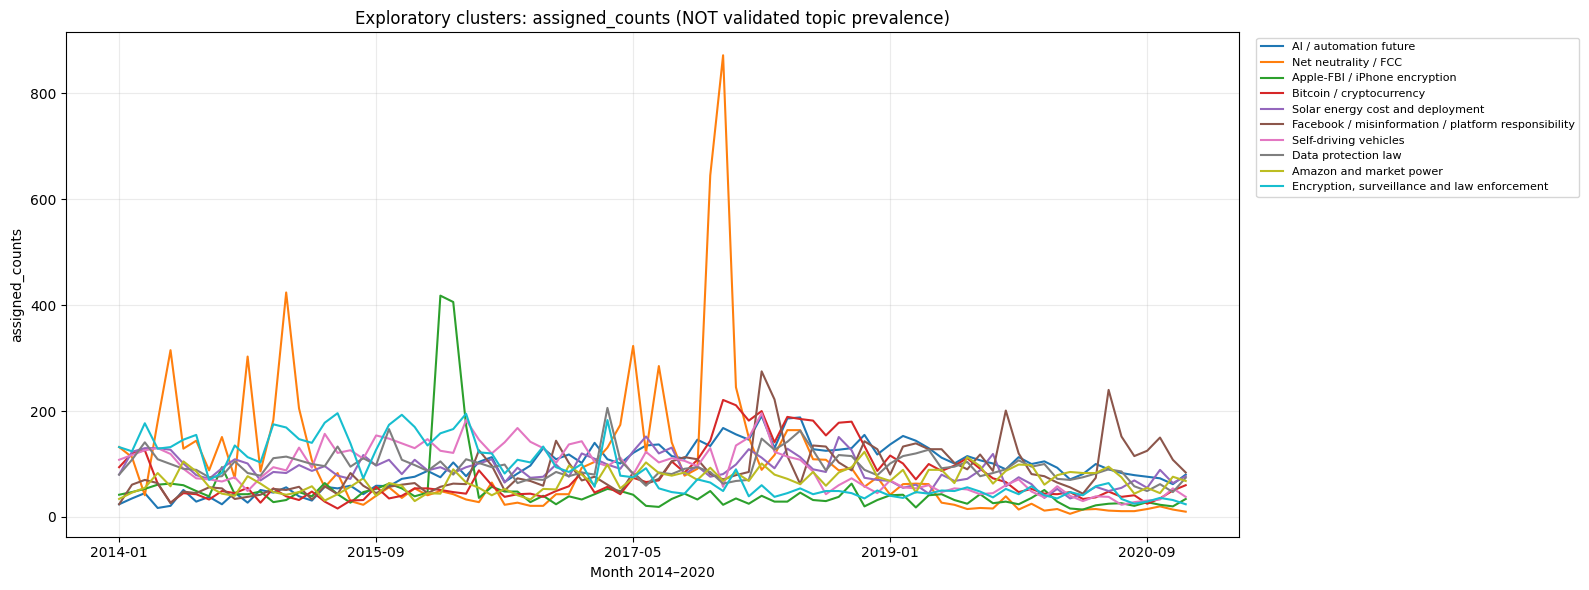

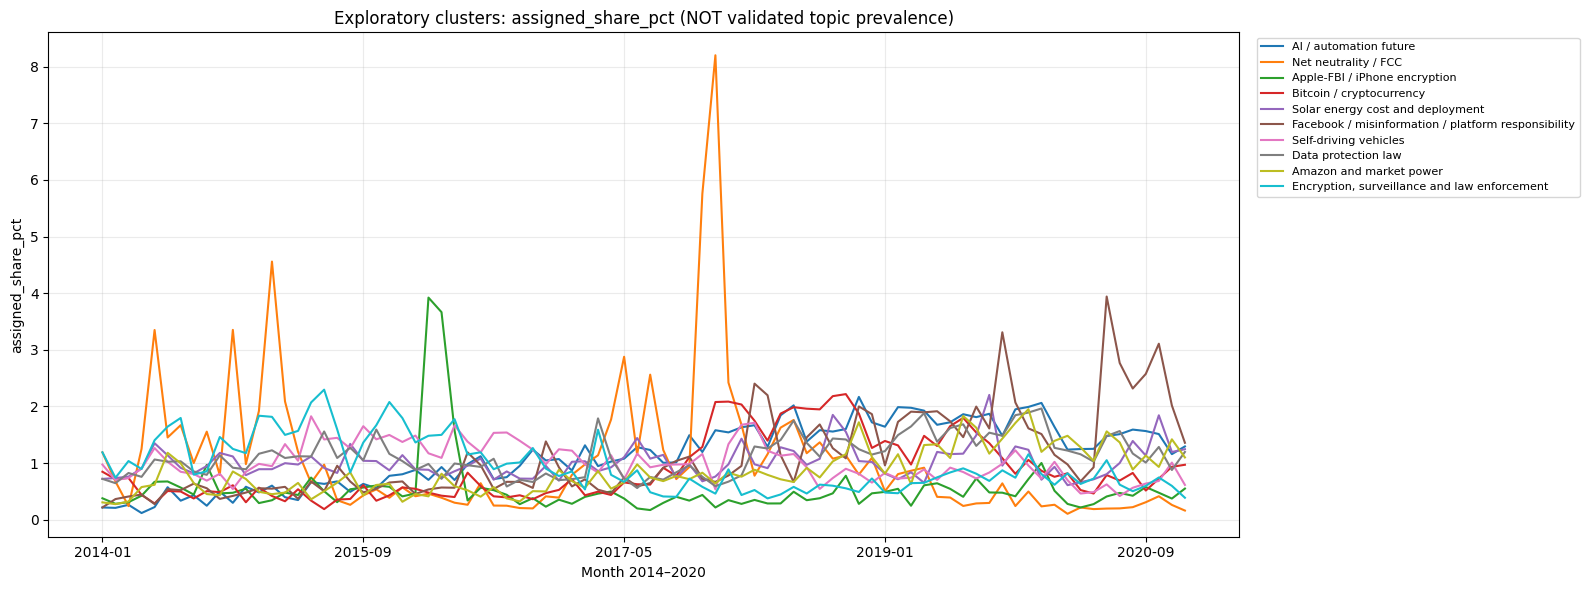

Temporal plots saved in: /content/drive/MyDrive/NarrativeCast/data/interim/task4/full_post_v4/quality_audit_v5/b33a176368c2


In [9]:
import matplotlib.pyplot as plt
cand_month=monthly[monthly.exploratory_cluster_id.isin(CANDIDATES)].copy()
counts=cand_month.pivot(index='month',columns='exploratory_cluster_id',values='assigned_post_count').fillna(0).sort_index()
shares=cand_month.pivot(index='month',columns='exploratory_cluster_id',values='assigned_share_pct_month').fillna(0).sort_index()
for dataframe,field in [(counts,'assigned_counts'),(shares,'assigned_share_pct')]:
    ax=dataframe.rename(columns=CANDIDATES).plot(figsize=(16,6),linewidth=1.5,title=f'Exploratory clusters: {field} (NOT validated topic prevalence)')
    ax.set_xlabel('Month 2014–2020');ax.set_ylabel(field);ax.grid(alpha=0.25)
    ax.legend(loc='upper left',bbox_to_anchor=(1.01,1.0),fontsize=8)
    plt.tight_layout()
    plt.savefig(OUT/f'candidate_{field}.png',dpi=150,bbox_inches='tight');plt.show()
print('Temporal plots saved in:',OUT)

## 8 — Phân tích **sau khi có nhãn người duyệt**; không tạo kết quả giả
Chỉ chạy sau khi đã nhập nhãn vào `review_queue_A.csv` (và B nếu có). Chỉ báo cáo precision với CI Wilson 95% khi **mọi mẫu ngẫu nhiên của ứng viên có nhãn YES/NO và cờ chất lượng**, không còn nhãn trống/UNCERTAIN; near/far/temporal phục vụ phân tích lỗi. Tỷ lệ thuộc cụm **không phải recall**. Một chủ đề có thể xuất hiện trong nhiều cụm hoặc bị miss hoàn toàn.

In [10]:
from math import sqrt
from sklearn.metrics import cohen_kappa_score

def wilson95(success,n):
    if n==0: return (np.nan,np.nan)
    z=1.959963984540054
    p=success/n;den=1+z*z/n
    ctr=(p+z*z/(2*n))/den
    margin=z*sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return (ctr-margin,ctr+margin)

def norm_text(s):return s.fillna('').astype(str).str.strip().str.upper()

A=pd.read_csv(A_FILE,dtype={'review_id':'string','post_id':'string'},keep_default_na=False)
assert A.review_id.is_unique and set(A.review_id)==set(queue.review_id)
A['topic_fit']=norm_text(A.topic_fit)
A['quality_flag']=norm_text(A.quality_flag)
allowed_fit={'','YES','NO','UNCERTAIN','NA'}
allowed_quality={'','CLEAN','SPAM_PROMO','NON_ENGLISH','OTHER_LOW_QUALITY','UNCERTAIN'}
assert set(A.topic_fit).issubset(allowed_fit), 'Unexpected topic_fit choice'
assert set(A.quality_flag).issubset(allowed_quality), 'Unexpected quality_flag choice'
A['fully_labeled']=A.topic_fit.isin({'YES','NO','UNCERTAIN','NA'}) & A.quality_flag.isin(allowed_quality-{''})
print('REVIEW A labels:',int(A.fully_labeled.sum()),'/',len(A), '(not-yet-reviewed: ',int((~A.fully_labeled).sum()),')')

rows=[]
for k,group in A[A.sampling_role.eq('cluster_random')].groupby('exploratory_cluster_id'):
    k=int(k)
    n_target=len(group)
    labeled=group[group.fully_labeled]
    n_labeled=len(labeled)
    yes=int((labeled.topic_fit=='YES').sum())
    uncertain=int((labeled.topic_fit=='UNCERTAIN').sum())
    na=int((labeled.topic_fit=='NA').sum())
    no=int((labeled.topic_fit=='NO').sum())
    # Only for candidate topics where all random cases are coded YES/NO (no UNCERTAIN/NA).
    valid_candidate=(k in CANDIDATES and n_labeled==n_target and uncertain==0 and na==0)
    measured=(yes/n_target) if valid_candidate else np.nan
    lo,hi=wilson95(yes,n_target) if valid_candidate else (np.nan,np.nan)
    clean_yes=int(((labeled.topic_fit=='YES') & (labeled.quality_flag=='CLEAN')).sum())
    cleanmeasured=(clean_yes/n_target) if valid_candidate else np.nan
    clo,chi=wilson95(clean_yes,n_target) if valid_candidate else (np.nan,np.nan)
    # Provisional bounds for fully annotated but unresolved uncertain candidate entries.
    complete_candidate=(k in CANDIDATES and n_labeled==n_target and na==0)
    lower_bound=yes/n_target if complete_candidate else np.nan
    upper_bound=(yes+uncertain)/n_target if complete_candidate else np.nan
    rows.append({'cluster_id':k,'candidate_hint':CANDIDATES.get(k,''),
        'random_total':n_target,'random_fully_labeled':n_labeled,'random_coded_yes':yes,
        'random_coded_no':no,'random_uncertain':uncertain,'random_not_applicable':na,
        'validated_topic_precision':measured,'topic_precision_ci_low':lo,'topic_precision_ci_high':hi,
        'confirmed_fit_lower_bound_if_complete':lower_bound,'possible_fit_upper_bound_if_complete':upper_bound,
        'validated_clean_topic_precision':cleanmeasured,
        'clean_ci_low':clo,'clean_ci_high':chi,
        'spam_promo_in_review':int((labeled.quality_flag=='SPAM_PROMO').sum()),
        'non_english_in_review':int((labeled.quality_flag=='NON_ENGLISH').sum()),
        'status': 'PRELIMINARY_PRECISION_READY' if valid_candidate and n_target>=CFG['min_candidate_random_labels'] else
                  'NON_CANDIDATE_SCREEN' if k not in CANDIDATES else
                  'REQUIRES_COMPLETION_OR_ADJUDICATION'})
res=pd.DataFrame(rows)
res=res.merge(summary[['exploratory_cluster_id','assigned_post_count','assigned_share_pct']],
              left_on='cluster_id',right_on='exploratory_cluster_id',how='left').drop(columns='exploratory_cluster_id')
res.sort_values(['candidate_hint','cluster_id'],inplace=True)
res.to_csv(OUT/'quality_estimates_from_human_labels.csv',index=False)
print('Saved quality estimates: NaN means not estimable yet, never fill NaN with 0.')
display(res[res.cluster_id.isin(CANDIDATES)])

# Independent double annotation check: only where both actual annotations are present.
B=pd.read_csv(B_FILE,dtype={'review_id':'string'},keep_default_na=False)
if len(B):
    for col in ['topic_fit','quality_flag']: B[col]=norm_text(B[col])
    agree=A[['review_id','topic_fit','quality_flag']].merge(B[['review_id','topic_fit','quality_flag']],on='review_id',suffixes=('_A','_B'),validate='one_to_one')
    stats=[]
    for col,allowed in [('topic_fit',{'YES','NO','UNCERTAIN'}),('quality_flag',allowed_quality-{''})]:
        ab=agree[agree[col+'_A'].isin(allowed)&agree[col+'_B'].isin(allowed)]
        if len(ab)>=2:
            labs=sorted(set(ab[col+'_A'])|set(ab[col+'_B']))
            kappa=cohen_kappa_score(ab[col+'_A'],ab[col+'_B'],labels=labs) if len(labs)>1 else np.nan
        else:kappa=np.nan
        stats.append({'field':col,'n_double_reviewed':len(ab),'kappa':kappa})
    pd.DataFrame(stats).to_csv(OUT/'inter_annotator_agreement.csv',index=False)
    display(pd.DataFrame(stats))

# Không auto chốt ngách; chỉ tạo dữ liệu ra quyết định.
result_status=('HUMAN_TOPIC_SELECTION_REQUIRED' if (res.loc[res.cluster_id.isin(CANDIDATES),'status']=='PRELIMINARY_PRECISION_READY').all() else 'PENDING_HUMAN_REVIEW')
print('FINAL TOPIC DECISION:',result_status)

REVIEW A labels: 0 / 2690 (not-yet-reviewed:  2690 )
Saved quality estimates: NaN means not estimable yet, never fill NaN with 0.


,cluster_id,candidate_hint,random_total,random_fully_labeled,random_coded_yes,random_coded_no,random_uncertain,random_not_applicable,validated_topic_precision,topic_precision_ci_low,...,confirmed_fit_lower_bound_if_complete,possible_fit_upper_bound_if_complete,validated_clean_topic_precision,clean_ci_low,clean_ci_high,spam_promo_in_review,non_english_in_review,status,assigned_post_count,assigned_share_pct
5,5,AI / automation future,80,0,0,0,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0,0,REQUIRES_COMPLETION_OR_ADJUDICATION,7913,1.052811
89,89,Amazon and market power,80,0,0,0,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0,0,REQUIRES_COMPLETION_OR_ADJUDICATION,5792,0.770615
50,50,Apple-FBI / iPhone encryption,80,0,0,0,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0,0,REQUIRES_COMPLETION_OR_ADJUDICATION,4112,0.547094
71,71,Bitcoin / cryptocurrency,80,0,0,0,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0,0,REQUIRES_COMPLETION_OR_ADJUDICATION,6447,0.857762
85,85,Data protection law,80,0,0,0,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0,0,REQUIRES_COMPLETION_OR_ADJUDICATION,8036,1.069176
114,114,"Encryption, surveillance and law enforcement",80,0,0,0,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0,0,REQUIRES_COMPLETION_OR_ADJUDICATION,7420,0.987218
73,73,Facebook / misinformation / platform responsib...,80,0,0,0,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0,0,REQUIRES_COMPLETION_OR_ADJUDICATION,7386,0.982694
44,44,Net neutrality / FCC,80,0,0,0,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0,0,REQUIRES_COMPLETION_OR_ADJUDICATION,8565,1.139558
75,75,Self-driving vehicles,80,0,0,0,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0,0,REQUIRES_COMPLETION_OR_ADJUDICATION,7813,1.039506
72,72,Solar energy cost and deployment,80,0,0,0,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0,0,REQUIRES_COMPLETION_OR_ADJUDICATION,7457,0.992141


,field,n_double_reviewed,kappa
0,topic_fit,0,NaN
1,quality_flag,0,NaN


FINAL TOPIC DECISION: PENDING_HUMAN_REVIEW


## 9 — Manifest / bảo vệ dữ liệu đầu ra
Tất cả file v4 để nguyên. Sau khi chấm, zip **review_queue_A.csv**, **review_queue_B_overlap.csv**, **quality_estimates_from_human_labels.csv**, **inter_annotator_agreement.csv**, `sample_manifest.csv`, `cluster_summary_v5.csv`, `cluster_monthly_profile.csv`, `cluster_annual_profile.csv`, `review_rubric.json` và notebook có output. **Không gửi 94 NPZ**.

**Điều kiện kết thúc ND3.4a:** đủ nhãn ngẫu nhiên, xem phản ví dụ far/temporal, kiểm tra chủ đề bị miss ở global_random, đánh giá framing qua nội dung thật, đưa ra tiêu chí và quyết định chốt ngách có chứng cứ. Trước đó không gọi nhiệm vụ là đã chọn domain.

In [11]:
manifest={
 'audit_id':AUDIT_ID,'source_run_hash':RUN_HASH,'source_full_post_rows':int(accept['full_post_rows']),
 'source_cluster_count':len(expected_sizes), 'source_month_count':len(months),
 'model':accept['model'],'embedding_dim':int(accept['embedding_dim']),
 'embedding_recomputed':False,'kmeans_refitted':False,'n_review_rows':int(len(sample)),
 'roles':{str(k):int(v) for k,v in sample.sampling_role.value_counts().items()},
 'output_path':str(OUT), 'data_quality_gate':'SAMPLE_AND_JOIN_PASS',
 'topic_selection':'PENDING_HUMAN_REVIEW',
 'limitations':['centroid nearest/farthest not probabilistic','cluster random precision not recall',
 'global screen finite sample may miss rare topics','2014-2020 analysis uses post shares not narrative gold',
 'label disagreement and missing labels must be reported'],
 'sampling_config':CFG,
}
(OUT/'v5_quality_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
print(json.dumps(manifest,indent=2,ensure_ascii=False))
print('NEXT: annotate A/B review CSV, return audit outputs; keep raw 94 embedding shards in Drive.')

{
  "audit_id": "b33a176368c2",
  "source_run_hash": "e7480e1fd1620bc2",
  "source_full_post_rows": 751607,
  "source_cluster_count": 120,
  "source_month_count": 84,
  "model": "sentence-transformers/all-MiniLM-L6-v2",
  "embedding_dim": 384,
  "embedding_recomputed": false,
  "kmeans_refitted": false,
  "n_review_rows": 2690,
  "roles": {
    "cluster_random": 1576,
    "global_random": 350,
    "far_centroid": 304,
    "near_centroid": 304,
    "temporal_year": 140,
    "temporal_control": 16
  },
  "output_path": "/content/drive/MyDrive/NarrativeCast/data/interim/task4/full_post_v4/quality_audit_v5/b33a176368c2",
  "data_quality_gate": "SAMPLE_AND_JOIN_PASS",
  "topic_selection": "PENDING_HUMAN_REVIEW",
  "limitations": [
    "centroid nearest/farthest not probabilistic",
    "cluster random precision not recall",
    "global screen finite sample may miss rare topics",
    "2014-2020 analysis uses post shares not narrative gold",
    "label disagreement and missing labels must be r